# 02 · Análisis exploratorio de datos (EDA)
**Fase CRISP-DM:** 2. Comprensión de los datos

**Objetivo:** entender cómo se comportan las variables, cómo se relacionan con la edad (Rings) y detectar problemas de calidad antes de limpiar.

El **EDA** (*Exploratory Data Analysis*) es como hacerle un chequeo médico a los datos antes de usarlos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RUTA_RAW = Path("..") / "data" / "raw" / "abalone.data"
RUTA_FIG = Path("..") / "docs" / "figuras"
RUTA_FIG.mkdir(parents=True, exist_ok=True)

COLUMNAS = ["Sex", "Length", "Diameter", "Height", "Whole_weight",
            "Shucked_weight", "Viscera_weight", "Shell_weight", "Rings"]
df = pd.read_csv(RUTA_RAW, header=None, names=COLUMNAS)
NUMERICAS = COLUMNAS[1:]   # todas menos Sex
print(df.shape)

(4177, 9)


## 1. Estadística descriptiva
- **mean** = promedio · **std** = qué tan dispersos están los datos · **min/max** = extremos · **25%, 50%, 75%** = cuartiles (el 50% es la mediana).

In [2]:
df.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.524,0.120,0.075,0.450,0.545,0.615,0.815
Diameter,4177.0,0.408,0.099,0.055,0.350,0.425,0.480,0.650
Height,4177.0,0.140,0.042,0.000,0.115,0.140,0.165,1.130
Whole_weight,4177.0,0.829,0.490,0.002,0.442,0.800,1.153,2.826
Shucked_weight,4177.0,0.359,0.222,0.001,0.186,0.336,0.502,1.488
Viscera_weight,4177.0,0.181,0.110,0.000,0.094,0.171,0.253,0.760
Shell_weight,4177.0,0.239,0.139,0.002,0.130,0.234,0.329,1.005
Rings,4177.0,9.934,3.224,1.000,8.000,9.000,11.000,29.000


👀 **Observa:** el mínimo de `Height` es **0**. Un abulón no puede medir 0 de altura, así que es un **error de captura**.

## 2. Variable categórica: Sex

Sex
M    1528
I    1342
F    1307
Name: count, dtype: int64
Sex
M    36.6 %
I    32.1 %
F    31.3 %
Name: count, dtype: str


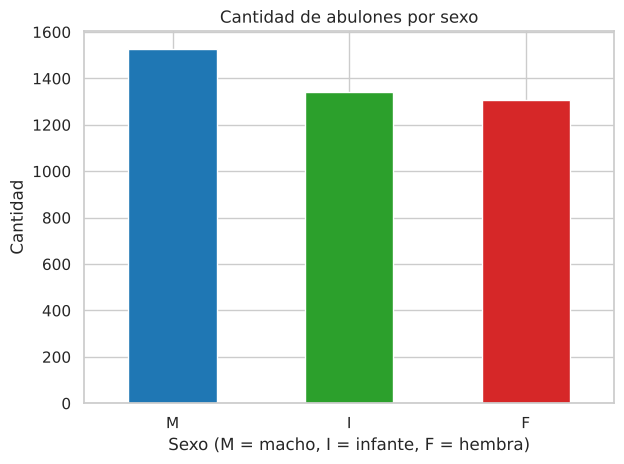

In [3]:
conteo = df["Sex"].value_counts()
print(conteo)
print((conteo / len(df) * 100).round(1).astype(str) + " %")

ax = conteo.plot(kind="bar", color=["#1F77B4", "#2CA02C", "#D62728"], rot=0)
ax.set_title("Cantidad de abulones por sexo")
ax.set_xlabel("Sexo (M = macho, I = infante, F = hembra)")
ax.set_ylabel("Cantidad")
plt.tight_layout()
plt.savefig(RUTA_FIG / "01_sexo.png", dpi=120)
plt.show()

Las tres categorías están **equilibradas** (alrededor de un tercio cada una), lo cual es bueno para el análisis.

## 3. Variable objetivo: Rings (edad)

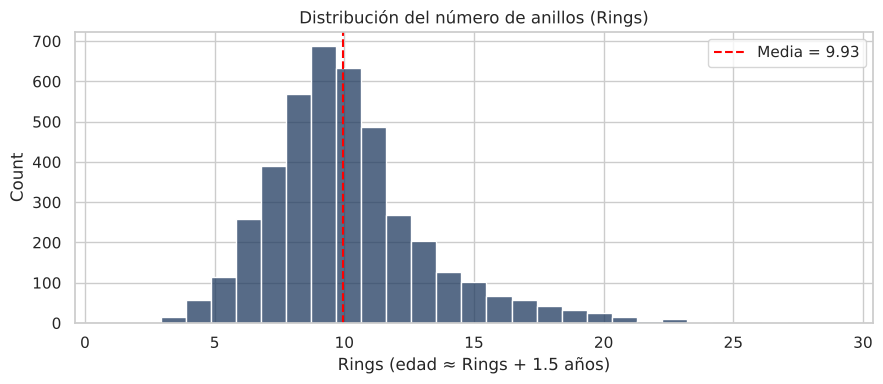

Cuartiles de Rings: {0.25: 8.0, 0.5: 9.0, 0.75: 11.0}


In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df["Rings"], bins=29, color="#1F3A5F", ax=ax)
ax.axvline(df["Rings"].mean(), color="red", linestyle="--", label=f"Media = {df['Rings'].mean():.2f}")
ax.set_title("Distribución del número de anillos (Rings)")
ax.set_xlabel("Rings (edad ≈ Rings + 1.5 años)")
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_FIG / "02_rings.png", dpi=120)
plt.show()

print("Cuartiles de Rings:", df["Rings"].quantile([0.25, 0.5, 0.75]).to_dict())

La mayoría de los abulones tienen entre **8 y 11 anillos**. La distribución tiene una "cola" hacia la derecha: hay pocos ejemplares muy viejos (hasta 29 anillos).

## 4. Distribución de las variables numéricas

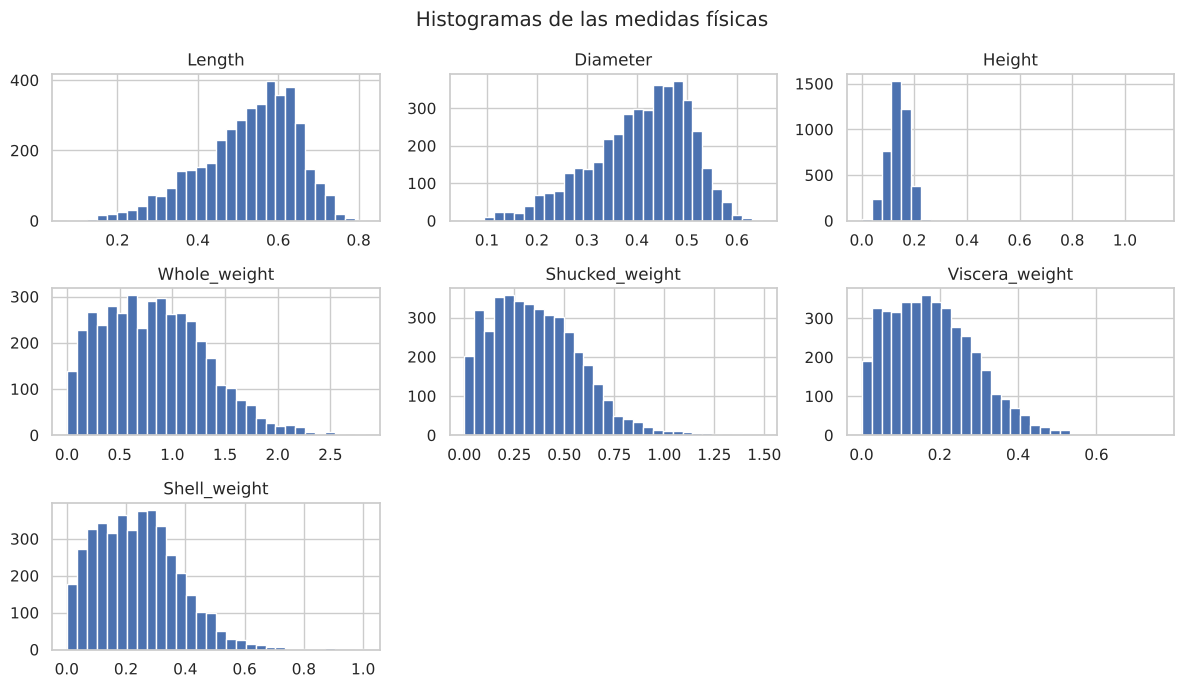

In [5]:
df[NUMERICAS[:-1]].hist(bins=30, figsize=(12, 7), color="#4C72B0")
plt.suptitle("Histogramas de las medidas físicas")
plt.tight_layout()
plt.savefig(RUTA_FIG / "03_histogramas.png", dpi=120)
plt.show()

## 5. Valores atípicos (outliers)
Un **diagrama de caja** muestra la mediana (línea), el 50% central de los datos (caja) y los puntos fuera de los "bigotes" (posibles atípicos).

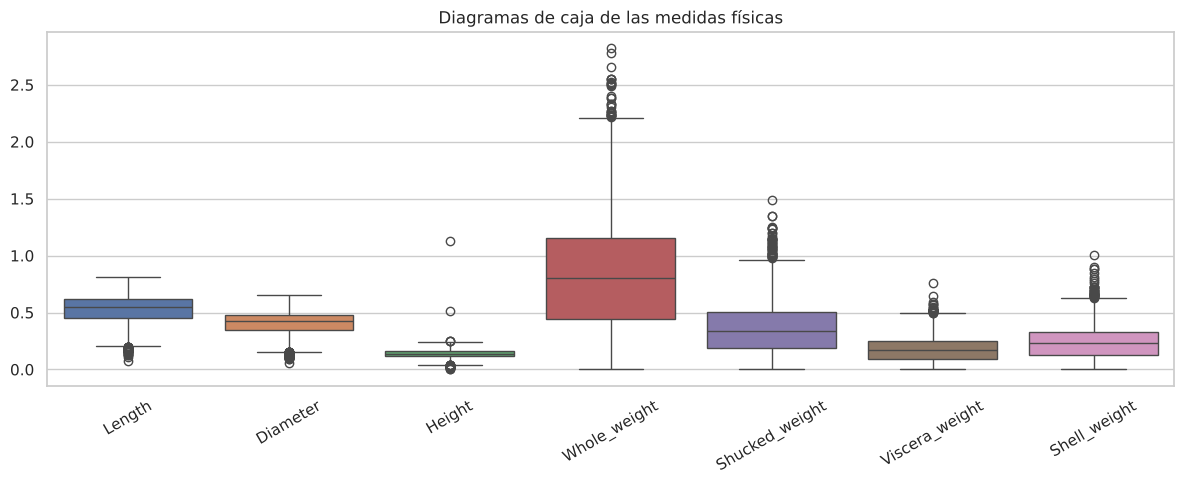

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df[NUMERICAS[:-1]], ax=ax)
ax.set_title("Diagramas de caja de las medidas físicas")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(RUTA_FIG / "04_boxplots.png", dpi=120)
plt.show()

In [7]:
# Conteo de atípicos con la regla IQR: fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR]
resumen = []
for col in NUMERICAS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    resumen.append({"Variable": col, "Atípicos (IQR)": fuera})
pd.DataFrame(resumen)

,Variable,Atípicos (IQR)
0,Length,49
1,Diameter,59
2,Height,29
3,Whole_weight,30
4,Shucked_weight,48
5,Viscera_weight,26
6,Shell_weight,35
7,Rings,278


📌 Ser "atípico" **no significa ser un error**: un abulón muy grande o muy viejo es raro, pero real. Solo eliminaremos valores **físicamente imposibles**.

## 6. Revisión de valores imposibles

In [8]:
altura_cero = df[df["Height"] == 0]
altura_extrema = df[df["Height"] > 0.3]
carne_mayor = df[df["Shucked_weight"] > df["Whole_weight"]]
concha_mayor = df[df["Shell_weight"] > df["Whole_weight"]]

print("Altura igual a 0:", len(altura_cero))
print("Altura extrema (> 0.3, más del doble que cualquier otro):", len(altura_extrema), altura_extrema["Height"].tolist())
print("Peso de la carne mayor que el peso total:", len(carne_mayor))
print("Peso de la concha mayor que el peso total:", len(concha_mayor))

Altura igual a 0: 2
Altura extrema (> 0.3, más del doble que cualquier otro): 2 [0.515, 1.13]
Peso de la carne mayor que el peso total: 4
Peso de la concha mayor que el peso total: 1


**Interpretación:**
- **Altura = 0** → imposible.
- **Altura de 0.515 y 1.13** → el resto de los abulones no pasa de 0.25; son casi seguro errores de captura (equivaldrían a 103 mm y 226 mm de alto).
- **Una parte pesa más que el abulón completo** → imposible.

Estos registros se tratarán en el notebook 03.

## 7. Relación entre variables (correlación)
La **correlación** va de -1 a 1. Cerca de **1** = cuando una sube, la otra también; cerca de **0** = no hay relación lineal.

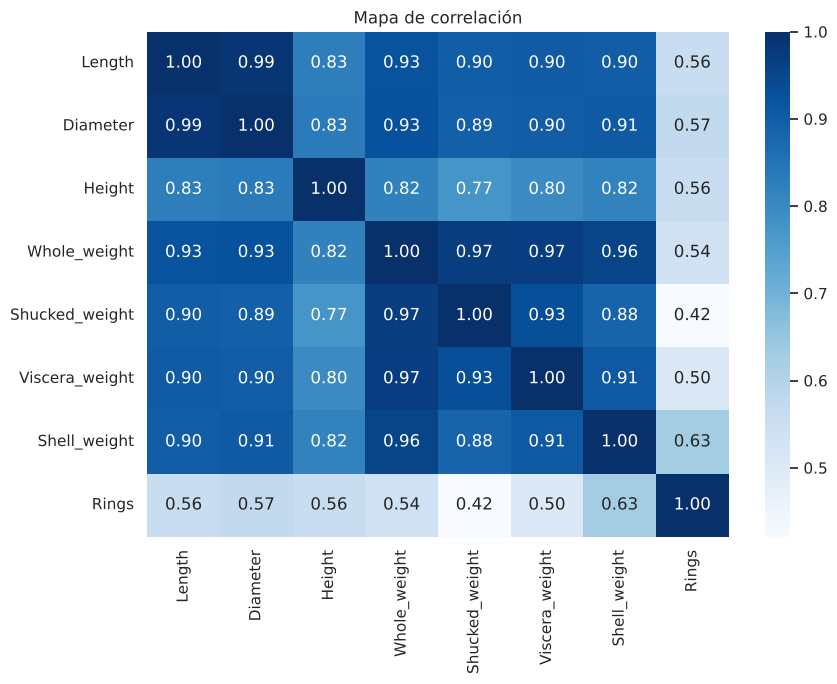

Correlación de cada variable con Rings:
Shell_weight      0.628
Diameter          0.575
Height            0.557
Length            0.557
Whole_weight      0.540
Viscera_weight    0.504
Shucked_weight    0.421
Name: Rings, dtype: float64


In [9]:
corr = df[NUMERICAS].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_title("Mapa de correlación")
plt.tight_layout()
plt.savefig(RUTA_FIG / "05_correlacion.png", dpi=120)
plt.show()

print("Correlación de cada variable con Rings:")
print(corr["Rings"].drop("Rings").sort_values(ascending=False).round(3))

**Hallazgos clave:**
- La variable más relacionada con la edad es **Shell_weight** (≈ 0.63).
- Las medidas físicas están **muy correlacionadas entre sí** (> 0.9). Eso justifica usar **PCA** en la Unidad IV para resumirlas.

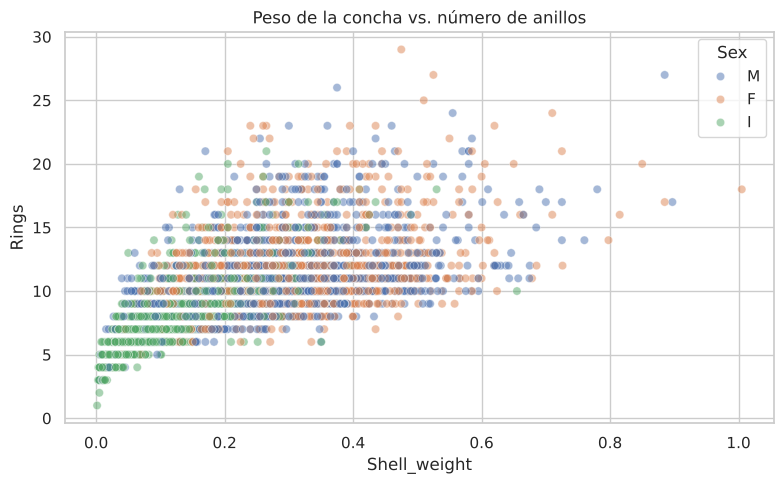

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="Shell_weight", y="Rings", hue="Sex", alpha=0.5, ax=ax)
ax.set_title("Peso de la concha vs. número de anillos")
plt.tight_layout()
plt.savefig(RUTA_FIG / "06_shell_vs_rings.png", dpi=120)
plt.show()

## 8. Edad por sexo

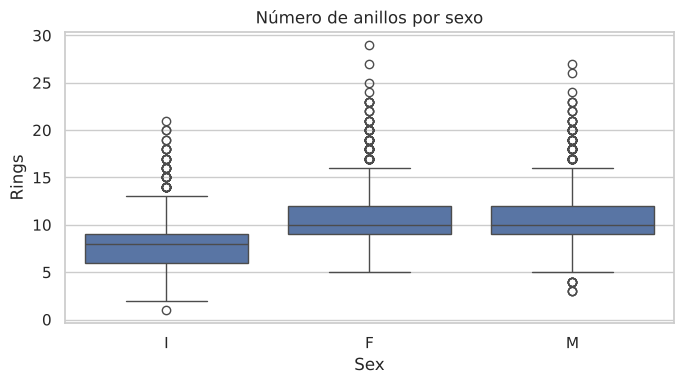

,count,mean,std,min,25%,50%,75%,max
Sex,,,,,,,,
F,1307.0,11.13,3.10,5.0,9.0,10.0,12.0,29.0
I,1342.0,7.89,2.51,1.0,6.0,8.0,9.0,21.0
M,1528.0,10.71,3.03,3.0,9.0,10.0,12.0,27.0


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="Sex", y="Rings", order=["I", "F", "M"], ax=ax)
ax.set_title("Número de anillos por sexo")
plt.tight_layout()
plt.savefig(RUTA_FIG / "07_rings_por_sexo.png", dpi=120)
plt.show()

df.groupby("Sex")["Rings"].describe().round(2)

Los **infantes (I)** tienen claramente menos anillos que machos y hembras; machos y hembras son muy parecidos. Por eso `Sex` (en especial "infante") será una variable útil para predecir la edad.

## 9. Conclusiones del EDA
1. No hay nulos ni duplicados.
2. Hay registros **físicamente imposibles** (alturas en 0 o extremas, partes que pesan más que el total) que deben eliminarse.
3. `Shell_weight` es la variable más relacionada con la edad.
4. Las medidas físicas están muy correlacionadas entre sí → útil para PCA.
5. Los infantes son claramente más jóvenes.